# Practice B4 · Single cell: neighbourhoods, not distances

**UMI counts → quality control → normalise → highly variable genes → PCA → UMAP and t-SNE → k-means clusters → dot plot and cluster names → what an embedding can and cannot show → draw order**

*Genomic Data Processing · Day 5 (10/27) · Data visualization in genetics and genomics · about 20 minutes*

> **All data in this practice are simulated (computer-generated). No real patient data are used.**
> The 2,940 cells carry real human gene symbols and Ensembl IDs (MANE Select, hg38), and well-known blood-cell marker
> genes are expressed at levels similar to public 10x Genomics PBMC data, so the marker logic you practise here is the
> same as in a real analysis.

**How to use this notebook.** Run the cells from top to bottom (Shift + Enter). Every step follows the same four beats:
**Question** (what we want to know) → **Test** (run the method, print numbers) → **Check** (compare with the planted
answer in a `# CHECK ·` cell) → **Visualize** (the figure that shows the result honestly).

* A CHECK line prints **✓** when your number is in the expected range and **✗** when it is not. If you see ✗, run the
  step again from its first cell before you go on.
* **Your turn** asks one short question. The answer is folded: click **Answer** to open it.
* The true cell type of every cell is in `data/truth/scrna_truth.tsv`. Open it **only** in the Check beats (from Step B4.4).
* UMAP needs the package `umap-learn` (`pip install umap-learn`). Without it the notebook still runs: it uses the UMAP
  coordinates stored in `data/scrna_cells.tsv` (made with the same settings), and Step B4.6 varies the t-SNE perplexity
  instead of the UMAP neighbours.

| Step | Topic | min |
|---|---|---|
| B4.1 | question, quality control | 3 |
| B4.2 | normalise, highly variable genes, PCA | 3 |
| B4.3 | UMAP and t-SNE | 3 |
| B4.4 | k-means clusters, adjusted Rand index | 3 |
| B4.5 | dot plot, cluster names | 3 |
| B4.6 | neighbourhoods, not distances | 4 |
| B4.7 | draw order, summary | 1 |

| File (`data/`) | What is inside |
|---|---|
| `scrna_counts.npz` | UMI counts: 2,940 cells (rows) × 2,000 genes (columns), a sparse matrix |
| `scrna_genes.tsv` | gene symbol and Ensembl gene ID of each column |
| `scrna_cells.tsv` | barcode, donor, UMIs, detected genes and a stored UMAP of each row (no cell types) |
| `scrna_markers.tsv` | marker genes of 8 blood cell types: prior knowledge from the literature, not the answer |
| `truth/scrna_truth.tsv` | the planted cell type of each cell (Check beats only) |

In [1]:
# Step 0 · Set-up: imports, folders and figure style
import os, sys, time
from pathlib import Path
ROOT = Path.cwd() if (Path.cwd() / "dviz.py").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
os.environ.setdefault("NUMBA_CACHE_DIR", str(ROOT / ".numba_cache"))   # needed by umap-learn on some systems
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import dviz
dviz.use_style()
DATA, FIG = ROOT / "data", ROOT / "results" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
T_START = time.time()
import scipy.sparse as sp, sklearn
from scipy.stats import spearmanr
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score
try:
    import umap                                   # optional: pip install umap-learn
    HAS_UMAP = True
except ImportError:
    HAS_UMAP = False
SEED = 0                                          # one seed for k-means, UMAP and t-SNE
print(f"numpy {np.__version__} · pandas {pd.__version__} · scikit-learn {sklearn.__version__} · umap-learn {umap.__version__ if HAS_UMAP else 'not installed'}")

numpy 2.5.4 · pandas 3.1.0 · scikit-learn 1.9.1 · umap-learn 0.5.12


## Step B4.1 · The question, and quality control of the cells  *(3 min)*

### Question

**Which immune cell types are in this blood sample, and what can a UMAP of the cells tell us – and what can it not?**

**Why this step.** Blood contains several kinds of immune cells: T cells and NK cells that kill infected cells, B cells
that make antibodies, and monocytes and dendritic cells that swallow microbes and show their pieces to T cells.
Single-cell RNA sequencing measures which genes each cell uses, so we can sort the cells into types without knowing
them in advance. Before any analysis we check that every cell contains a sensible number of molecules: droplets with
very few are often empty or broken, and droplets with very many may contain two cells.

**New terms**
* **Cell barcode** – a 16-letter DNA tag shared by all molecules from one droplet, i.e. from one cell (`AAACCTGAGAAGGCCT-1`).
* **UMI (unique molecular identifier)** – a random tag on every captured mRNA molecule; counting UMIs counts molecules, not PCR copies.
* **Count matrix** – one row per cell, one column per gene; each entry is a number of UMIs.
* **Sparse matrix** – a matrix stored as its non-zero entries only; single-cell matrices are mostly zeros.
* **Library size** – the total number of UMIs in one cell.

### Test

We load the data, then compute two numbers per cell that describe its quality: the **library size** (UMIs per cell)
and the number of **detected genes** (genes with at least one UMI). We also count in how many cells each gene is seen.

In [2]:
# Step B4.1 · load the count matrix, the gene table, the cell table and the marker lists
counts = sp.load_npz(DATA / "scrna_counts.npz").tocsr()         # cells x genes, UMI counts (sparse)
genes = pd.read_csv(DATA / "scrna_genes.tsv", sep="\t")          # one row per column of `counts`
cells = pd.read_csv(DATA / "scrna_cells.tsv", sep="\t")          # one row per row of `counts`
markers_table = pd.read_csv(DATA / "scrna_markers.tsv", sep="\t")
MARKERS = {r.cell_type: r.markers.split(",") for r in markers_table.itertuples()}
print(f"count matrix: {counts.shape[0]:,} cells x {counts.shape[1]:,} genes; {counts.nnz:,} entries are not 0")
print(cells.head(3).to_string(index=False))
print(genes.head(3).to_string(index=False))
print(markers_table.head(3).to_string(index=False))

count matrix: 2,940 cells x 2,000 genes; 510,083 entries are not 0
           cell_id donor  n_counts  n_genes   umap1   umap2
AAAAAAAGACCGTCCC-1    D2      1709      160 10.9784  1.1956
AAAAACTGTCTTATAG-1    D4      2566      204 -3.9492 -5.7374
AAAAAGTTGGCGTCCG-1    D2      2057      164 13.0569  2.4006
    gene            gene_id
    HES4 ENSG00000188290.13
 TNFRSF4 ENSG00000186827.13
TNFRSF14 ENSG00000157873.20
   cell_type                        markers
 Naive CD4 T       CCR7,LEF1,TCF7,SELL,IL7R
Memory CD4 T S100A4,GPR183,ANXA1,KLRB1,IL7R
       CD8 T            CD8A,CD8B,CCL5,GZMK


In [3]:
# Step B4.1 · quality control: UMIs and detected genes per cell, cells per gene
umis_per_cell = np.asarray(counts.sum(axis=1)).ravel()            # library size of each cell
genes_per_cell = np.asarray((counts > 0).sum(axis=1)).ravel()     # genes with at least 1 UMI
cells_per_gene = np.asarray((counts > 0).sum(axis=0)).ravel()
pct_zeros = 100 * (1 - counts.nnz / (counts.shape[0] * counts.shape[1]))
keep_gene = cells_per_gene >= 3                                   # usual filter: gene seen in >= 3 cells
qc = pd.DataFrame({"UMIs per cell": umis_per_cell, "genes per cell": genes_per_cell})
print(qc.describe(percentiles=[0.01, 0.5, 0.99]).round(0).to_string())
print(f"zeros: {pct_zeros:.1f}% of all entries")
print(f"genes seen in >= 3 cells: {keep_gene.sum():,} of {keep_gene.size:,} (the others are removed)")
print(f"cells with fewer than 200 detected genes: {(genes_per_cell < 200).sum():,}")

       UMIs per cell  genes per cell
count         2940.0          2940.0
mean          2370.0           173.0
std            956.0            27.0
min            544.0            96.0
1%             935.0           119.0
50%           2188.0           171.0
99%           5485.0           246.0
max           7412.0           284.0
zeros: 91.3% of all entries
genes seen in >= 3 cells: 1,840 of 2,000 (the others are removed)
cells with fewer than 200 detected genes: 2,426


### Check

In [4]:
# CHECK · size of the data and typical 10x numbers
dviz.check("B4.n_cells", counts.shape[0], 2940)
dviz.check("B4.n_genes", counts.shape[1], 2000)
dviz.check("B4.median_umis", float(np.median(umis_per_cell)), between=(1800, 2600), note="UMIs per cell")
dviz.check("B4.umis_min", int(umis_per_cell.min()), between=(300, 1000), note="smallest library")
dviz.check("B4.umis_max", int(umis_per_cell.max()), between=(5000, 10000), note="largest library")
dviz.check("B4.median_genes", float(np.median(genes_per_cell)), between=(100, 400), note="of a 2,000-gene panel")
dviz.check("B4.pct_zeros", round(pct_zeros, 2), between=(90, 99), note="% of matrix entries that are 0")
dviz.check("B4.genes_kept", int(keep_gene.sum()), between=(1700, 2000), note="genes seen in >= 3 cells")
dviz.check("B4.cells_below_200_genes", int((genes_per_cell < 200).sum()), between=(1470, 2940))
dviz.check("B4.cells_table_matches", bool((cells["n_counts"].to_numpy() == umis_per_cell).all()), True)

CHECK ✓ B4.n_cells = 2,940   (reference: 2940)
CHECK ✓ B4.n_genes = 2,000   (reference: 2000)
CHECK ✓ B4.median_umis = 2,188   (reference: in [1800, 2600])  UMIs per cell
CHECK ✓ B4.umis_min = 544   (reference: in [300, 1000])  smallest library
CHECK ✓ B4.umis_max = 7,412   (reference: in [5000, 10000])  largest library
CHECK ✓ B4.median_genes = 171   (reference: in [100, 400])  of a 2,000-gene panel
CHECK ✓ B4.pct_zeros = 91.33   (reference: in [90, 99])  % of matrix entries that are 0
CHECK ✓ B4.genes_kept = 1,840   (reference: in [1700, 2000])  genes seen in >= 3 cells
CHECK ✓ B4.cells_below_200_genes = 2,426   (reference: in [1470, 2940])
CHECK ✓ B4.cells_table_matches = True   (reference: True)


True

### Visualize

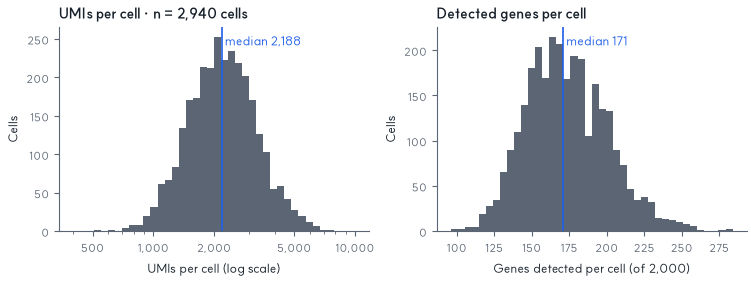

In [5]:
# Step B4.1 · histograms of UMIs and of detected genes per cell
fig, axs = plt.subplots(1, 2, figsize=(7.5, 2.8), layout="constrained")
axs[0].hist(umis_per_cell, bins=np.geomspace(400, 10_000, 41), color=dviz.SLATE)
axs[0].set_xscale("log")
axs[0].set_xticks([500, 1000, 2000, 5000, 10000], ["500", "1,000", "2,000", "5,000", "10,000"])
axs[0].xaxis.set_minor_formatter(plt.NullFormatter())
axs[0].set(xlabel="UMIs per cell (log scale)", ylabel="Cells", title=f"UMIs per cell · n = {len(cells):,} cells")
axs[1].hist(genes_per_cell, bins=40, color=dviz.SLATE)
axs[1].set(xlabel="Genes detected per cell (of 2,000)", ylabel="Cells", title="Detected genes per cell")
for ax, values in zip(axs, [umis_per_cell, genes_per_cell]):
    med = np.median(values)
    ax.axvline(med, color=dviz.BLUE, lw=1.2)
    ax.text(med, ax.get_ylim()[1] * 0.97, f" median {med:,.0f}", color=dviz.BLUE, va="top")
dviz.savefig(fig, "B4_qc")
plt.show()

**What changed?** Nothing in the data yet – we only measured. The median cell has 2,188 UMIs
(from 544 to 7,412) and 171 detected genes, and
91.3% of all matrix entries are 0, as in real 10x data. 1,840 of the
2,000 genes are seen in at least 3 cells; the others will be removed.

**Your turn.** Many tutorials remove cells with fewer than 200 detected genes. How many cells would that remove here,
and why is this rule wrong for this matrix?

<details><summary>Answer</summary>

2,426 of the 2,940 cells. The rule was made for full matrices with 20,000–30,000
genes, where a healthy blood cell shows several hundred to a thousand genes. Our matrix holds a 2,000-gene panel, so a
normal cell shows only about 171. Choose QC thresholds from your own distributions (for
example, cells far below the median), never copy them blindly.
</details>

## Step B4.2 · Normalise, pick highly variable genes, run PCA  *(3 min)*

**Why this step.** Cells are captured with different efficiency: a cell with 4,000 UMIs shows every gene about twice as
often as a cell of the same type with 2,000. **Normalising** removes this depth effect. Most genes vary only because of
counting noise, so we keep the **highly variable genes**, which carry the biology. **PCA** then summarises these 1,000
genes in 30 numbers per cell: it keeps the main patterns and averages away much of the noise.

**New terms**
* **Counts per 10,000** – divide each count by the cell's library size and multiply by 10,000, so that every cell sums to 10,000.
* **log1p** – log(1 + x). It compresses large values and keeps 0 at 0 (log 0 would be minus infinity).
* **Highly variable gene (HVG)** – a gene whose variance across cells is larger than that of genes with a similar mean.
* **Dispersion** – variance divided by mean; it is z-scored among genes with a similar mean (the Seurat / Scanpy method).
* **Principal component (PC)** – a weighted sum of genes that captures as much variation as possible; PC1 captures the most.
* **Scree plot** – the variance explained by each PC; where the curve flattens, noise starts.

### Test

In [6]:
# Step B4.2 · helper: normalise every cell to 10,000 UMIs, then log1p
def normalise_log1p(counts, target=10_000):
    """Scale every cell to `target` UMIs, then take log(1 + x).

    counts: cells x genes (scipy sparse or numpy). Returns (lognorm, scaled) as dense arrays.
    """
    X = counts.toarray() if hasattr(counts, "toarray") else np.asarray(counts)
    X = X.astype(np.float64)
    umis = X.sum(axis=1, keepdims=True)          # UMIs per cell (library size)
    scaled = X / umis * target                   # every row now sums to `target`
    return np.log1p(scaled), scaled

In [7]:
# Step B4.2 · normalise and log-transform; follow the smallest and the largest cell through the step
counts_kept = counts[:, keep_gene]                         # drop genes seen in fewer than 3 cells
gene_names = genes["gene"].to_numpy()[keep_gene]
lognorm, scaled = normalise_log1p(counts_kept)
ex = [int(np.argmin(umis_per_cell)), int(np.argmax(umis_per_cell))]
j = int(np.flatnonzero(gene_names == "ACTB")[0])           # ACTB: a gene that every cell uses
example = pd.DataFrame({"UMIs in cell": umis_per_cell[ex], "ACTB UMIs": counts_kept[ex, j].toarray().ravel(),
                        "ACTB per 10,000": scaled[ex, j].round(1), "log1p": lognorm[ex, j].round(2),
                        "row sum after scaling": scaled[ex].sum(axis=1).round(1)},
                       index=cells["cell_id"].to_numpy()[ex])
print(example.to_string())

                    UMIs in cell  ACTB UMIs  ACTB per 10,000  log1p  row sum after scaling
TAGCAATCGTATTGAA-1           544         12            220.6    5.4                10000.0
ATTGGATACCTGTCTG-1          7412        243            327.8    5.8                10000.0


In [8]:
# Step B4.2 · helper: highly variable genes (dispersion z-score within bins of similar mean)
def highly_variable_genes(scaled, n_top=1000, n_bins=20):
    """Indices of the n_top genes that vary most compared with genes of similar mean.

    Dispersion = variance / mean of the normalised counts. Genes are put into n_bins bins of
    equal size by mean, and dispersions are z-scored inside each bin (Seurat / Scanpy idea).
    """
    mean = scaled.mean(axis=0)
    var = scaled.var(axis=0, ddof=1)
    log_disp = np.log(var / mean)
    bins = pd.qcut(np.log1p(mean), n_bins, labels=False, duplicates="drop")
    z = pd.Series(log_disp).groupby(bins).transform(lambda d: (d - d.mean()) / d.std())
    order = np.argsort(-z.to_numpy(), kind="stable")
    return np.sort(order[:n_top]), z.to_numpy()

In [9]:
# Step B4.2 · keep the 1,000 most variable genes; are the known marker genes among them?
hvg, hvg_z = highly_variable_genes(scaled, n_top=1000)
hvg_names = set(gene_names[hvg])
marker_genes = sorted({g for gs in MARKERS.values() for g in gs})
missed = [g for g in marker_genes if g not in hvg_names]
print(f"{len(hvg):,} HVGs; marker genes among them: {len(marker_genes) - len(missed)} of {len(marker_genes)}")
print("marker genes not selected:", missed)

1,000 HVGs; marker genes among them: 31 of 35
marker genes not selected: ['ANXA1', 'CCR7', 'GPR183', 'SELL']


In [10]:
# Step B4.2 · helper: PCA (centred; scale=True would z-score every gene first)
def run_pca(lognorm_hvg, n_pcs=30, scale=False, seed=0):
    """PCA of the log-normalised HVG values (PCA subtracts each gene's mean itself).

    scale=True first z-scores every gene (clipped at 10), as Seurat's ScaleData does.
    Returns (cell scores: cells x n_pcs, fraction of variance explained by each PC).
    """
    from sklearn.decomposition import PCA
    X = lognorm_hvg
    if scale:
        X = np.clip((X - X.mean(axis=0)) / X.std(axis=0, ddof=1), -10, 10)
    pca = PCA(n_components=n_pcs, svd_solver="full", random_state=seed)
    scores = pca.fit_transform(X)
    signs = np.sign(scores[np.abs(scores).argmax(axis=0), np.arange(n_pcs)])
    return scores * signs, pca.explained_variance_ratio_      # fixed signs: same picture every run

In [11]:
# Step B4.2 · PCA of the 1,000 HVGs: 30 numbers (PC scores) per cell
pcs, var_ratio = run_pca(lognorm[:, hvg], n_pcs=30, seed=SEED)
print("PC scores:", pcs.shape, "(cells x PCs)")
print("variance explained (%), PC1-PC10:", np.round(100 * var_ratio[:10], 1))
print(f"PC1-PC3: {100 * var_ratio[:3].sum():.1f}%   PC1-PC30: {100 * var_ratio.sum():.1f}%   "
      f"PC8-PC30: {100 * var_ratio[7:].mean():.2f}% each on average")

PC scores: (2940, 30) (cells x PCs)
variance explained (%), PC1-PC10: [37.7 11.1  7.3  1.6  1.3  1.   0.9  0.5  0.5  0.5]
PC1-PC3: 56.1%   PC1-PC30: 70.2%   PC8-PC30: 0.40% each on average


### Check

In [12]:
# CHECK · every cell sums to 10,000 after scaling; 1,000 HVGs; most markers kept; a few strong PCs
dviz.check("B4.rowsum_max_error", float(np.abs(scaled.sum(axis=1) - 10_000).max()), between=(0, 0.01),
           note="largest |row sum - 10,000| after scaling")
dviz.check("B4.hvg_n", len(hvg), 1000)
dviz.check("B4.markers_in_hvg", len(marker_genes) - len(missed), between=(28, len(marker_genes)),
           note=f"of {len(marker_genes)} marker genes")
dviz.check("B4.pc1_3_var_pct", round(100 * var_ratio[:3].sum(), 1), between=(30, 90), note="% variance, PC1-PC3")
dviz.check("B4.pc8_30_mean_var_pct", round(100 * var_ratio[7:].mean(), 2), between=(0, 1), note="% per PC: noise level")

CHECK ✓ B4.rowsum_max_error = 1.819e-12   (reference: in [0, 0.01])  largest |row sum - 10,000| after scaling
CHECK ✓ B4.hvg_n = 1,000   (reference: 1000)
CHECK ✓ B4.markers_in_hvg = 31   (reference: in [28, 35])  of 35 marker genes
CHECK ✓ B4.pc1_3_var_pct = 56.1   (reference: in [30, 90])  % variance, PC1-PC3
CHECK ✓ B4.pc8_30_mean_var_pct = 0.4   (reference: in [0, 1])  % per PC: noise level


True

### Visualize

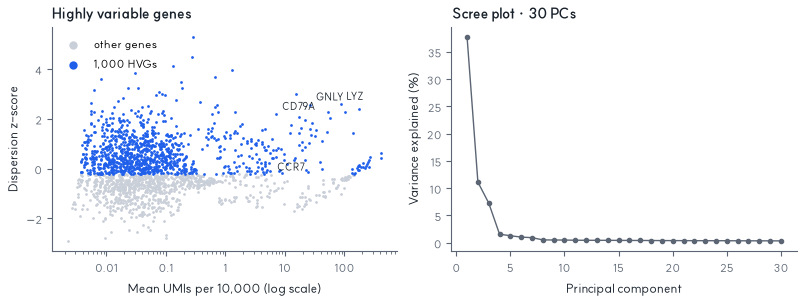

In [13]:
# Step B4.2 · left: which genes are highly variable; right: scree plot (variance explained per PC)
mean_expr = scaled.mean(axis=0)
is_hvg = np.isin(np.arange(scaled.shape[1]), hvg)
fig, axs = plt.subplots(1, 2, figsize=(8, 3), layout="constrained")
axs[0].scatter(mean_expr[~is_hvg], hvg_z[~is_hvg], s=4, color=dviz.GREY, linewidths=0, label="other genes")
axs[0].scatter(mean_expr[is_hvg], hvg_z[is_hvg], s=4, color=dviz.BLUE, linewidths=0, label="1,000 HVGs")
for g in ["LYZ", "GNLY", "CD79A", "CCR7"]:
    k = int(np.flatnonzero(gene_names == g)[0])
    axs[0].annotate(g, (mean_expr[k], hvg_z[k]), xytext=(4, 3), textcoords="offset points", fontsize=7, color=dviz.INK)
axs[0].set(xscale="log", xlabel="Mean UMIs per 10,000 (log scale)", ylabel="Dispersion z-score",
           title="Highly variable genes")
axs[0].set_xticks([0.01, 0.1, 1, 10, 100], ["0.01", "0.1", "1", "10", "100"])
axs[0].xaxis.set_minor_formatter(plt.NullFormatter())
axs[0].legend(loc="upper left", markerscale=3)
axs[1].plot(np.arange(1, 31), 100 * var_ratio, "o-", color=dviz.SLATE, ms=3, lw=1)
axs[1].set(xlabel="Principal component", ylabel="Variance explained (%)", title="Scree plot · 30 PCs")
dviz.savefig(fig, "B4_hvg_pca")
plt.show()

**What changed?** Raw counts of 2,000 genes became log-normalised values of 1,840 genes; before
the log every cell sums to 10,000, so the smallest and the largest cell can be compared (ACTB per 10,000 is similar in
both, although their raw counts differ several-fold). 31 of the 35 marker genes are among the
1,000 HVGs; the missed ones (ANXA1, CCR7, GPR183, SELL) are used by several cell types, so they vary less than strictly
type-specific genes. PC1–PC3 explain 56.1% of the variance; after about PC 7 each PC
explains only about 0.40% – mostly noise.

**Your turn.** Why does the scree plot flatten after about PC 7?

<details><summary>Answer</summary>

Eight cell types differ along at most 7 independent directions (8 points always fit into 7 dimensions). Once these
directions are captured, the remaining PCs mostly describe counting noise, each about
0.40% of the variance. Using 30 PCs is safe: the extra PCs add a little noise but
no false structure.
</details>

## Step B4.3 · UMAP and t-SNE: a 2-D map of the cells  *(3 min)*

**Why this step.** Thirty numbers per cell are still too many to look at. **t-SNE** and **UMAP** place every cell on a
2-D map so that cells with similar expression end up close together. Both start from each cell's nearest neighbours in
the 30-PC space and then arrange the cells so that neighbours stay neighbours. The result depends on the settings and
on a random start, so we fix the **seed** and **report the settings and the run time**.

**New terms**
* **Embedding** – a low-dimensional (here 2-D) picture of high-dimensional data.
* **k nearest neighbours (k-NN)** – the k cells most similar to a given cell.
* **n_neighbors (UMAP)** – how many neighbours each cell considers: small = very local picture, large = more global.
* **min_dist (UMAP)** – how tightly points may be packed on the map.
* **Perplexity (t-SNE)** – roughly how many neighbours each cell pays attention to (30 is the usual default).
* **Seed** – the starting number of the random number generator; the same seed gives the same picture.

### Test

In [14]:
# Step B4.3 · helpers: UMAP and t-SNE with fixed settings, timed
def run_umap(pcs, n_neighbors=15, min_dist=0.3, seed=0):
    """UMAP of the PCs with fixed settings. Returns (embedding, seconds)."""
    import umap
    t0 = time.time()
    emb = umap.UMAP(n_neighbors=n_neighbors, min_dist=min_dist, random_state=seed,
                    n_jobs=1).fit_transform(pcs)
    return emb, time.time() - t0

def run_tsne(pcs, perplexity=30, seed=0):
    """t-SNE of the PCs (scikit-learn, Barnes-Hut, PCA initialisation). Returns (embedding, seconds)."""
    from sklearn.manifold import TSNE
    t0 = time.time()
    emb = TSNE(perplexity=perplexity, init="pca", learning_rate="auto",
               random_state=seed).fit_transform(pcs)
    return emb, time.time() - t0

In [15]:
# Step B4.3 · UMAP (15 neighbours, min_dist 0.3) and t-SNE (perplexity 30), both from the 30 PCs
if HAS_UMAP:
    umap15, umap_seconds = run_umap(pcs, n_neighbors=15, min_dist=0.3, seed=SEED)
else:                                   # fallback: the same settings, computed by build/make_scrna.py
    umap15, umap_seconds = cells[["umap1", "umap2"]].to_numpy(), float("nan")
tsne30, tsne_seconds = run_tsne(pcs, perplexity=30, seed=SEED)
UMAP_SETTINGS = f"UMAP of 30 PCs (1,000 HVGs) · n_neighbors 15 · min_dist 0.3 · seed {SEED}"
print(f"{UMAP_SETTINGS} · {umap_seconds:.1f} s ({'computed now' if HAS_UMAP else 'stored fallback'})")
print(f"t-SNE of 30 PCs · perplexity 30 · PCA initialisation · seed {SEED} · {tsne_seconds:.1f} s")

UMAP of 30 PCs (1,000 HVGs) · n_neighbors 15 · min_dist 0.3 · seed 0 · 8.0 s (computed now)
t-SNE of 30 PCs · perplexity 30 · PCA initialisation · seed 0 · 2.7 s


### Check

In [16]:
# CHECK · one finite 2-D point per cell in both embeddings; run times recorded
for name, emb in [("B4.umap_ok", umap15), ("B4.tsne_ok", tsne30)]:
    dviz.check(name, bool(emb.shape == (len(cells), 2) and np.isfinite(emb).all()), True)
if HAS_UMAP:
    dviz.check("B4.umap_runtime_s", round(umap_seconds, 1), between=(0, 60), note="seconds (first call also compiles code)")
dviz.check("B4.tsne_runtime_s", round(tsne_seconds, 1), between=(0, 60), note="seconds")

CHECK ✓ B4.umap_ok = True   (reference: True)
CHECK ✓ B4.tsne_ok = True   (reference: True)
CHECK ✓ B4.umap_runtime_s = 8   (reference: in [0, 60])  seconds (first call also compiles code)
CHECK ✓ B4.tsne_runtime_s = 2.7   (reference: in [0, 60])  seconds


True

### Visualize

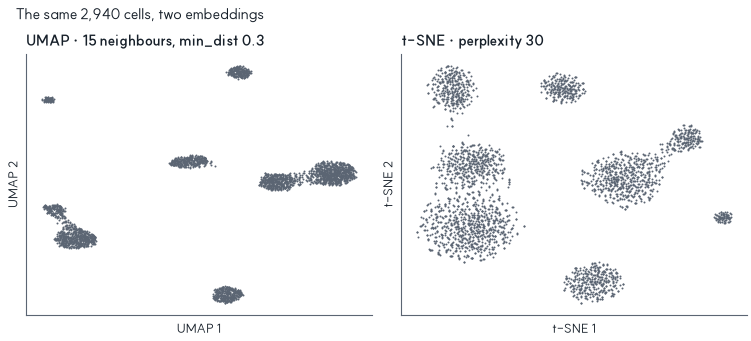

In [17]:
# Step B4.3 · the two maps before we know any clusters (the axes have no units, so no numbers)
fig, axs = plt.subplots(1, 2, figsize=(7.5, 3.4), layout="constrained")
for ax, emb, method, title in [(axs[0], umap15, "UMAP", "UMAP · 15 neighbours, min_dist 0.3"),
                               (axs[1], tsne30, "t-SNE", "t-SNE · perplexity 30")]:
    ax.scatter(emb[:, 0], emb[:, 1], s=2, color=dviz.SLATE, linewidths=0)
    ax.set(title=title, xticks=[], yticks=[], xlabel=f"{method} 1", ylabel=f"{method} 2")
fig.suptitle(f"The same {len(cells):,} cells, two embeddings", x=0.02, ha="left", color=dviz.INK)
dviz.savefig(fig, "B4_embeddings")
plt.show()

**What changed?** Every cell now has two coordinates per method. Both maps show separate islands of cells – but the
islands sit in different places, and their sizes and the gaps between them differ between the two methods. The run
times are printed above; write them down together with the settings.

**Your turn.** Change the seed of UMAP to 1 (`run_umap(pcs, n_neighbors=15, min_dist=0.3, seed=1)`). What changes in
the picture, and what stays the same?

<details><summary>Answer</summary>

The islands move, rotate or mirror, and inside an island the exact neighbours are partly reshuffled: only
28% of each cell's 15 nearest neighbours are the same on both maps. What stays
is the grouping: on the seed-1 map 99% of a cell's neighbours are
still in its own k-means cluster (seed 0: 99%), and the map keeps as
many 30-PC neighbours as before (15.6% vs 15.8%). This is why we fix and report the
seed. The k-means clusters in Step B4.4 do not change at all, because they are computed from the 30 PCs, not from the map.
</details>

## Step B4.4 · k-means clusters, checked with the adjusted Rand index  *(3 min)*

**Why this step.** Our eyes see islands, but we cluster in the 30-PC space, because the 2-D map distorts distances.
**k-means** splits the cells into k groups so that every cell is close to the centre of its group. We ask for k = 8
because the experiment was designed with 8 cell types; in real data you would try several k (or a graph method such
as Leiden) and justify the choice.

**New terms**
* **Cluster** – a group of cells that are more similar to each other than to the other cells.
* **k-means** – start with k centres; give each cell to its nearest centre; move each centre to the mean of its cells;
  repeat. `n_init=10` tries 10 starts and keeps the best one.
* **Adjusted Rand index (ARI)** – agreement between two groupings that ignores the group names: 1 = identical,
  about 0 = no better than random.

### Test

In [18]:
# Step B4.4 · k-means with k = 8 on the 30 PCs (not on the 2-D map)
km = KMeans(n_clusters=8, n_init=10, random_state=SEED).fit(pcs)
cluster = km.labels_                                       # one number 0-7 per cell
print("cells per cluster:", pd.Series(cluster).value_counts().sort_index().to_dict())

cells per cluster: {0: 553, 1: 721, 2: 353, 3: 332, 4: 235, 5: 470, 6: 79, 7: 197}


### Check

Now we may open the truth. We join it to our cells **by barcode**, never by row order.

In [19]:
# CHECK · compare the clusters with the planted cell types (open the truth file only here)
truth = pd.read_csv(DATA / "truth" / "scrna_truth.tsv", sep="\t")
truth = cells[["cell_id"]].merge(truth, on="cell_id", how="left", validate="one_to_one")   # join by barcode
assert truth["cell_type"].notna().all() and (truth["cell_id"] == cells["cell_id"]).all()
true_type = truth["cell_type"].to_numpy()
ari = adjusted_rand_score(true_type, cluster)
dviz.check("B4.ari", round(ari, 3), between=(0.9, 1.0), note="adjusted Rand index, k-means (k = 8) vs truth")
table = pd.crosstab(pd.Series(true_type, name="true type"), pd.Series(cluster, name="cluster"))
print(table.to_string())

CHECK ✓ B4.ari = 0.962   (reference: in [0.9, 1.0])  adjusted Rand index, k-means (k = 8) vs truth
cluster         0    1    2    3    4    5   6    7
true type                                          
B               0    0  353    0    0    0   0    0
CD14 Mono     550    0    0    0    0    0   0    9
CD8 T           0    1    0  332    0    5   0    0
DC              0    0    0    0    0    0  79    0
FCGR3A Mono     3    0    0    0    0    0   0  188
Memory CD4 T    0   20    0    0    0  459   0    0
NK              0    0    0    0  235    0   0    0
Naive CD4 T     0  700    0    0    0    6   0    0


### Visualize

In [20]:
# Step B4.4 · colours for the 8 cell types (Okabe-Ito; yellow replaced by dark gold, visible on white)
CELL_TYPES = ["Naive CD4 T", "Memory CD4 T", "CD8 T", "NK", "B", "CD14 Mono", "FCGR3A Mono", "DC"]
CT_COLORS = dict(zip(CELL_TYPES, ["#0072B2", "#E69F00", "#009E73", "#D55E00", "#56B4E9", "#CC79A7", "#8C6D1F", "#000000"]))

In [21]:
# Step B4.4 · helper: direct labels next to each cluster
def label_clusters(ax, emb, labels, fontsize=None, color="#17202A", halo=3):
    """Write each cluster's name next to its cells (direct labels, no legend to look up).

    Each name starts at the cluster's median position; adjustText (if installed) then pushes it off
    the points and draws a thin line back to the cluster.
    """
    import matplotlib.patheffects as pe
    labels = np.asarray(labels)
    texts = []
    for name in pd.unique(labels):
        x, y = np.median(emb[labels == name], axis=0)
        texts.append(ax.text(x, y, name, ha="center", va="center", fontsize=fontsize, color=color,
                             path_effects=[pe.withStroke(linewidth=halo, foreground="white")]))
    ax.margins(0.1)                                    # room for labels at the edges
    try:
        from adjustText import adjust_text
        step = max(1, len(emb) // 1500)                # avoid (a sample of) the points as well
        adjust_text(texts, x=emb[::step, 0], y=emb[::step, 1], ax=ax, expand=(1.1, 1.3), iter_lim=25,
                    arrowprops=dict(arrowstyle="-", color="#5B6573", lw=0.6))   # fixed iterations: same result every run
    except ImportError:
        pass
    return texts

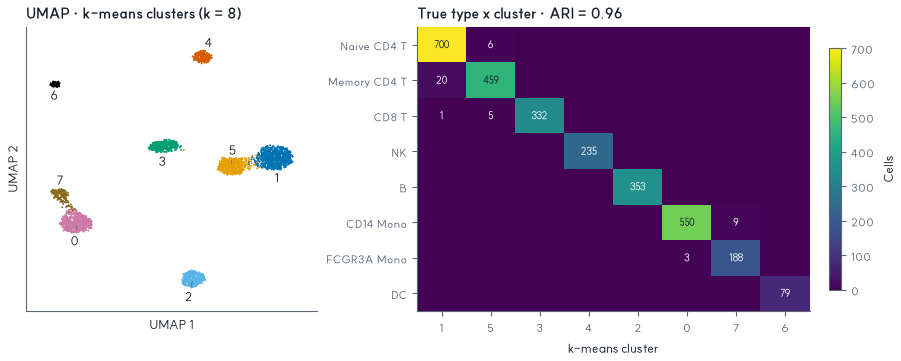

In [22]:
# Step B4.4 · left: UMAP coloured by k-means cluster; right: the truth-by-cluster table as a heatmap
table = table.loc[CELL_TYPES]
cols = sorted(table.columns, key=lambda c: CELL_TYPES.index(table[c].idxmax()))    # near-diagonal order
fig, axs = plt.subplots(1, 2, figsize=(9, 3.6), layout="constrained", gridspec_kw={"width_ratios": [1, 1.35]})
palette = {c: CT_COLORS[table[c].idxmax()] for c in cols}                          # colour = majority type
axs[0].scatter(umap15[:, 0], umap15[:, 1], s=2, c=[palette[c] for c in cluster], linewidths=0)
label_clusters(axs[0], umap15, cluster.astype(str))
axs[0].set(title="UMAP · k-means clusters (k = 8)", xticks=[], yticks=[], xlabel="UMAP 1", ylabel="UMAP 2")
M = table[cols].to_numpy()
im = axs[1].imshow(M, cmap="viridis", aspect="auto")
for (i, k), n in np.ndenumerate(M):
    if n > 0:
        axs[1].text(k, i, f"{n}", ha="center", va="center", fontsize=7, color="white" if n < 0.6 * M.max() else dviz.INK)
axs[1].set_xticks(range(len(cols)), [str(c) for c in cols])
axs[1].set_yticks(range(len(CELL_TYPES)), CELL_TYPES)
axs[1].set(xlabel="k-means cluster", title=f"True type x cluster · ARI = {ari:.2f}")
fig.colorbar(im, ax=axs[1], label="Cells", shrink=0.85)
dviz.savefig(fig, "B4_clusters")
plt.show()

**What changed?** Every cell now has a cluster number from 0 to 7. ARI = 0.962: each cluster is
almost entirely one true type, so the heatmap is nearly diagonal. The few disagreements (off-diagonal numbers) are
between close relatives: naive and memory CD4 T cells (26 cells), CD14 and FCGR3A
monocytes (12), and CD8 T cells grouped with CD4 T cells (6).

**Your turn.** Cluster the 2-D UMAP coordinates instead (`KMeans(n_clusters=8, n_init=10, random_state=SEED).fit(umap15)`).
Is the ARI higher or lower? Why is clustering the 2-D map a bad habit even when it looks fine?

<details><summary>Answer</summary>

On this map the ARI is 0.954 (30 PCs: 0.962). Whatever the number,
the map depends on n_neighbors, min_dist and the seed (Step B4.6), and it squeezes and stretches distances, so clusters
drawn on it inherit these arbitrary choices. Clusters computed in the 30-PC space do not.
</details>

## Step B4.5 · Dot plot of marker genes, and names for the clusters  *(3 min)*

**Why this step.** Cluster numbers mean nothing to a biologist. We name clusters with **prior knowledge**: genes known
from the literature to mark each cell type (`data/scrna_markers.tsv`), for example MS4A1 (the B-cell protein CD20) or
LYZ (lysozyme, made by monocytes). A **dot plot** shows two numbers for every gene and cluster at once and avoids the
overplotting of thousands of points.

**New terms**
* **Marker gene** – a gene expressed mainly in one cell type.
* **Dot plot** – one dot per gene (column) and cluster (row): **size** = % of the cluster's cells with at least one UMI;
  **colour** = mean expression in the cluster (scaled from 0 to 1 for each gene).
* **Annotation** – giving clusters biological names. Here: z-score each marker's mean across the clusters, average the
  z-scores of each cell type's markers, and give each cluster the best-scoring cell type.

### Test

In [23]:
# Step B4.5 · helpers: dot-plot numbers, and names from marker scores
def dotplot_table(counts_genes, lognorm_genes, clusters, gene_names):
    """Per cluster and gene: % of cells with any UMI, and mean log expression (all cells)."""
    clusters = pd.Series(np.asarray(clusters), name="cluster")
    expressing = pd.DataFrame(np.asarray(counts_genes) > 0, columns=gene_names).astype(float)
    level = pd.DataFrame(np.asarray(lognorm_genes), columns=gene_names)
    pct = 100 * expressing.groupby(clusters).mean()
    mean = level.groupby(clusters).mean()
    return pct, mean

def annotate_clusters(mean_table, markers):
    """Give each cluster the cell type whose marker genes are highest in it.

    mean_table: clusters x genes (mean log expression); markers: {cell type: [genes]}.
    Each gene is z-scored across clusters, so every marker counts equally.
    """
    z = (mean_table - mean_table.mean()) / mean_table.std(ddof=0)
    score = pd.DataFrame({t: z[g].mean(axis=1) for t, g in markers.items()})
    return score.idxmax(axis=1), score

In [24]:
# Step B4.5 · dot-plot numbers for the marker genes, then a name for every cluster
dot_genes = list(dict.fromkeys(g for gs in MARKERS.values() for g in gs))      # 35 genes, each once
gi = [int(np.flatnonzero(gene_names == g)[0]) for g in dot_genes]
pct, mean = dotplot_table(counts_kept[:, gi].toarray(), lognorm[:, gi], cluster, dot_genes)
cluster_label, score = annotate_clusters(mean, MARKERS)
print("marker score (mean z-score) of every cluster for every cell type:")
print(score.round(1).to_string())
print(cluster_label.rename("name").to_frame().T.to_string())

marker score (mean z-score) of every cluster for every cell type:
         Naive CD4 T  Memory CD4 T  CD8 T   NK    B  CD14 Mono  FCGR3A Mono   DC
cluster                                                                         
0               -0.4           0.2   -0.5 -0.6 -0.4        1.9          0.5  0.2
1                1.7          -0.5   -0.5 -0.6 -0.4       -0.7         -0.6 -0.6
2               -0.1          -0.6   -0.5 -0.6  2.6       -0.6         -0.6 -0.5
3                0.6           0.3    2.4  0.7 -0.4       -0.7         -0.6 -0.5
4               -0.6           0.0    0.5  2.4 -0.4       -0.7          0.0 -0.5
5                0.5           1.2   -0.2 -0.4 -0.4       -0.7         -0.6 -0.5
6               -0.8          -0.5   -0.6 -0.5 -0.3        0.6         -0.2  2.3
7               -0.9          -0.1   -0.5 -0.5 -0.4        1.0          2.1  0.2
cluster          0            1  2      3   4             5   6            7
name     CD14 Mono  Naive CD4 T  B  CD8 T  NK  

### Check

In [25]:
# CHECK · 8 different names; per-cell names vs truth; composition of the sample
cell_label = pd.Series(cluster).map(cluster_label).to_numpy()
correct = cell_label == true_type
dviz.check("B4.labels_unique", int(cluster_label.nunique()), 8, note="8 clusters -> 8 different names")
dviz.check("B4.pct_correct", round(100 * correct.mean(), 1), between=(95, 100), note="% of cells named correctly")
per_type = pd.DataFrame({"cells": pd.Series(true_type).value_counts(),
                         "% named correctly": pd.Series(correct).groupby(true_type).mean().mul(100).round(1)})
composition = pd.DataFrame({"truth (%)": pd.Series(true_type).value_counts(normalize=True).mul(100).round(1),
                            "our names (%)": pd.Series(cell_label).value_counts(normalize=True).mul(100).round(1)})
per_type = per_type.join(composition).loc[CELL_TYPES]
print(per_type.to_string())
dviz.check("B4.n_wrong", int((~correct).sum()), between=(0, 147), note="cells with a wrong name (5% = 147)")
dviz.check("B4.pct_cd14_mono", float(per_type.loc["CD14 Mono", "truth (%)"]), 19.0, tol=0.05, note="% of cells")
dviz.check("B4.pct_memory_cd4", float(per_type.loc["Memory CD4 T", "truth (%)"]), 16.3, tol=0.05, note="% of cells")

CHECK ✓ B4.labels_unique = 8   (reference: 8)  8 clusters -> 8 different names
CHECK ✓ B4.pct_correct = 98.5   (reference: in [95, 100])  % of cells named correctly
              cells  % named correctly  truth (%)  our names (%)
Naive CD4 T     706               99.2       24.0           24.5
Memory CD4 T    479               95.8       16.3           16.0
CD8 T           338               98.2       11.5           11.3
NK              235              100.0        8.0            8.0
B               353              100.0       12.0           12.0
CD14 Mono       559               98.4       19.0           18.8
FCGR3A Mono     191               98.4        6.5            6.7
DC               79              100.0        2.7            2.7
CHECK ✓ B4.n_wrong = 44   (reference: in [0, 147])  cells with a wrong name (5% = 147)
CHECK ✓ B4.pct_cd14_mono = 19   (reference: 19.0 ± 0.05)  % of cells
CHECK ✓ B4.pct_memory_cd4 = 16.3   (reference: 16.3 ± 0.05)  % of cells


True

### Visualize

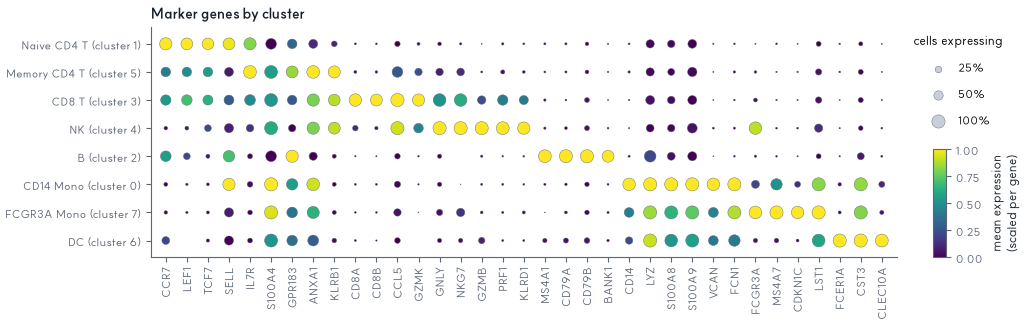

In [26]:
# Step B4.5 · dot plot: dot size = % of cells with any UMI; colour = mean expression, scaled 0-1 per gene
rows = [cluster_label[cluster_label == t].index[0] for t in CELL_TYPES]           # one cluster per type
size = pct.loc[rows, dot_genes].to_numpy()
level = mean.loc[rows, dot_genes]
level01 = ((level - level.min()) / (level.max() - level.min())).to_numpy()       # 0 = lowest, 1 = highest cluster
xx, yy = np.meshgrid(np.arange(len(dot_genes)), np.arange(len(rows)))
fig, ax = plt.subplots(figsize=(10.5, 3.6))
fig.subplots_adjust(left=0.13, right=0.84, bottom=0.26, top=0.9)
dots = ax.scatter(xx.ravel(), yy.ravel(), s=size.ravel() * 0.9, c=level01.ravel(), cmap="viridis",
                  vmin=0, vmax=1, edgecolors=dviz.SLATE, linewidths=0.3)
ax.set_xticks(range(len(dot_genes)), dot_genes, rotation=90)
ax.set_yticks(range(len(rows)), [f"{cluster_label[r]} (cluster {r})" for r in rows])
ax.set(xlim=(-0.7, len(dot_genes) - 0.3), ylim=(len(rows) - 0.4, -0.6), title="Marker genes by cluster")
for p in (25, 50, 100):
    ax.scatter([], [], s=p * 0.9, color=dviz.GREY, edgecolors=dviz.SLATE, linewidths=0.3, label=f"{p}%")
ax.legend(title="cells expressing", loc="upper left", bbox_to_anchor=(1.01, 1.02), labelspacing=1.1)
cax = fig.add_axes([0.875, 0.26, 0.012, 0.3])
fig.colorbar(dots, cax=cax, label="mean expression\n(scaled per gene)")
dviz.savefig(fig, "B4_dotplot")
plt.show()

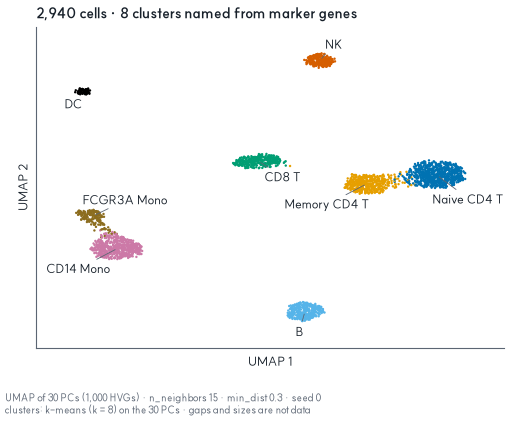

In [27]:
# Step B4.5 · UMAP coloured and labelled directly by cell type, with the settings under the plot
fig, ax = plt.subplots(figsize=(5.2, 4.4))
fig.subplots_adjust(left=0.08, right=0.98, top=0.9, bottom=0.17)
ax.scatter(umap15[:, 0], umap15[:, 1], s=3, c=[CT_COLORS[t] for t in cell_label], linewidths=0)
label_clusters(ax, umap15, cell_label)
ax.set(xticks=[], yticks=[], xlabel="UMAP 1", ylabel="UMAP 2",
       title=f"{len(cells):,} cells · 8 clusters named from marker genes")
fig.text(0.02, 0.015, UMAP_SETTINGS + "\nclusters: k-means (k = 8) on the 30 PCs · gaps and sizes are not data",
         fontsize=7, color=dviz.SLATE, va="bottom")
dviz.savefig(fig, "B4_umap_labelled")
plt.show()

**What changed?** The 8 numbers became 8 names, one per cell type, and 98.5% of the cells
carry the right name (44 cells are wrong). The dot plot is the evidence for each name: for example
MS4A1 and CD79A are seen in 95% and 99% of the B-cluster cells but in at most
15% of the cells of any other cluster. The sample consists of
24.0% naive CD4 T cells, 19.0% CD14
monocytes and 16.3% memory CD4 T cells (truth); our names give almost the same shares.

**Your turn.** Naive and memory CD4 T cells share most markers. Which genes in the dot plot tell them apart?

<details><summary>Answer</summary>

CCR7, LEF1, TCF7 and SELL are higher in naive cells (CCR7 is seen in 87% of the naive-cluster
cells and 53% of the memory-cluster cells), whereas S100A4, ANXA1, KLRB1 and GPR183 are higher
in memory cells (S100A4: 96% vs 67%). IL7R is in both. Because
the difference is a matter of degree, these two clusters also share most of the wrongly named cells.
</details>

## Step B4.6 · Neighbourhoods, not distances  *(4 min)*

### Question

**On a UMAP, what can we trust: who is next to whom, or how far apart the clusters are?**

**Why this step.** t-SNE and UMAP are built from each cell's nearest neighbours, so they try to keep neighbours
together; they make no promise about distances between clusters. We measure both properties for several embeddings of
the same cells: (1) how many of each cell's 15 nearest neighbours in the 30-PC space are still among its 15 nearest
neighbours on the 2-D map, and (2) whether the 28 distances between the 8 cluster centres keep their order.

**New terms**
* **15-NN kept** – the share of a cell's 15 nearest neighbours in the 30-PC space that are also its 15 nearest
  neighbours on the map, averaged over all cells. A random map would keep 15 / 2,939 ≈ 0.5%.
* **Same-label neighbours** – the share of a cell's 15 nearest neighbours on the map that carry the same cluster name.
* **Cluster centre (centroid)** – the mean position of the cells of one cluster.
* **Spearman ρ** – a correlation of ranks: 1 = the 28 distances have the same order as in the 30-PC space, 0 = an
  unrelated order.

### Test

In [28]:
# Step B4.6 · helpers: local structure (neighbours)
def knn_overlap(high, low, k=15):
    """Average fraction of each cell's k nearest neighbours in `high` (e.g. 30 PCs)
    that are also among its k nearest neighbours in `low` (a 2-D embedding). 1 = all kept."""
    from sklearn.neighbors import NearestNeighbors
    nn_high = NearestNeighbors(n_neighbors=k).fit(high).kneighbors(return_distance=False)
    nn_low = NearestNeighbors(n_neighbors=k).fit(low).kneighbors(return_distance=False)
    shared = [np.intersect1d(a, b).size for a, b in zip(nn_high, nn_low)]
    return float(np.mean(shared) / k)

def same_label_neighbours(emb, labels, k=15):
    """Share of each cell's k nearest neighbours (in `emb`) that carry the same label as the cell."""
    from sklearn.neighbors import NearestNeighbors
    labels = np.asarray(labels)
    nn = NearestNeighbors(n_neighbors=k).fit(emb).kneighbors(return_distance=False)
    return float((labels[nn] == labels[:, None]).mean())

In [29]:
# Step B4.6 · helpers: global structure (distances between cluster centres)
def centroid_distances(emb, labels):
    """Distance between the centres (means) of every pair of clusters in one embedding."""
    from scipy.spatial.distance import pdist
    labels = np.asarray(labels)
    names = sorted(set(labels))
    centres = np.array([emb[labels == c].mean(axis=0) for c in names])
    pairs = [f"{a} | {b}" for i, a in enumerate(names) for b in names[i + 1:]]
    return pd.Series(pdist(centres), index=pairs)

def isolation(dist):
    """Mean distance from each cluster centre to all other centres (input: centroid_distances)."""
    rows = [(name, d) for pair, d in dist.items() for name in pair.split(" | ")]
    table = pd.DataFrame(rows, columns=["cluster", "distance"])
    return table.groupby("cluster")["distance"].mean().sort_values(ascending=False)

In [30]:
# Step B4.6 · the same cells embedded more ways: PCA (2 PCs), t-SNE, UMAP with 5, 15 and 200 neighbours
embeddings = {"PCA (PC1, PC2)": pcs[:, :2], "t-SNE, perplexity 30": tsne30, "UMAP, 15 neighbours": umap15}
extra = ({"UMAP, 5 neighbours": 5, "UMAP, 200 neighbours": 200} if HAS_UMAP
         else {"t-SNE, perplexity 5": 5, "t-SNE, perplexity 100": 100})   # without umap-learn
for name, k in extra.items():
    t0 = time.time()
    if HAS_UMAP:
        embeddings[name] = run_umap(pcs, n_neighbors=k, min_dist=0.3, seed=SEED)[0]
    else:
        embeddings[name] = run_tsne(pcs, perplexity=k, seed=SEED)[0]
    print(f"{name}: {time.time() - t0:.1f} s")
KEY = {"PCA (PC1, PC2)": "pca2", "t-SNE, perplexity 30": "tsne30", "UMAP, 15 neighbours": "umap15",
       "UMAP, 5 neighbours": "umap5", "UMAP, 200 neighbours": "umap200",
       "t-SNE, perplexity 5": "tsne5", "t-SNE, perplexity 100": "tsne100"}

UMAP, 5 neighbours: 3.9 s
UMAP, 200 neighbours: 7.4 s


In [31]:
# Step B4.6 · per embedding: neighbours kept (local) and order of the cluster-centre distances (global)
ref_dist = centroid_distances(pcs, cell_label)            # 28 distances between the 8 centres in 30-PC space
rows_emb = [{"embedding": "30 PCs (reference)", "15-NN kept (%)": 100.0,
             "same-label neighbours (%)": 100 * same_label_neighbours(pcs, cell_label),
             "centre-distance rho": 1.0, "most isolated cluster": isolation(ref_dist).index[0]}]
for name, emb in embeddings.items():
    dist = centroid_distances(emb, cell_label)
    rows_emb.append({"embedding": name, "15-NN kept (%)": 100 * knn_overlap(pcs, emb, k=15),
                     "same-label neighbours (%)": 100 * same_label_neighbours(emb, cell_label),
                     "centre-distance rho": spearmanr(ref_dist, dist).statistic,
                     "most isolated cluster": isolation(dist).index[0]})
summary_emb = pd.DataFrame(rows_emb).set_index("embedding").round(2)
chance = 100 * 15 / (len(cells) - 1)
print(summary_emb.to_string())
print(f"chance level of '15-NN kept': {chance:.2f}%")

                      15-NN kept (%)  same-label neighbours (%)  centre-distance rho most isolated cluster
embedding                                                                                                 
30 PCs (reference)            100.00                      97.57                 1.00                    NK
PCA (PC1, PC2)                  6.34                      87.35                 0.96                    NK
t-SNE, perplexity 30           28.99                      98.11                 0.49                 CD8 T
UMAP, 15 neighbours            15.81                      98.81                 0.41                     B
UMAP, 5 neighbours             16.84                      98.03                 0.67                    NK
UMAP, 200 neighbours           12.44                      99.20                 0.36                    NK
chance level of '15-NN kept': 0.51%


### Check

In [32]:
# CHECK · neighbourhoods are kept far above chance; distances between clusters are not kept consistently
nonlinear = summary_emb.drop(index=["30 PCs (reference)", "PCA (PC1, PC2)"])
for name, kept in nonlinear["15-NN kept (%)"].items():
    dviz.check(f"B4.knn_{KEY[name]}_pct", round(kept, 1), between=(round(10 * chance, 1), 100),
               note=f"{name}: >= 10 x chance")
dviz.check("B4.knn_pca2_pct", round(summary_emb.loc["PCA (PC1, PC2)", "15-NN kept (%)"], 1),
           between=(0, round(nonlinear["15-NN kept (%)"].min(), 1)), note="a linear 2-D view keeps fewer")
dviz.check("B4.same_label_min_pct", round(nonlinear["same-label neighbours (%)"].min(), 1), between=(95, 100),
           note="t-SNE / UMAP: neighbours have the same name")
rho = summary_emb["centre-distance rho"].drop(index="30 PCs (reference)")
dviz.check("B4.rho_range", round(rho.max() - rho.min(), 2), between=(0.3, 2),
           note=f"rho from {rho.min():.2f} to {rho.max():.2f}")
dviz.check("B4.n_isolated_answers", int(summary_emb["most isolated cluster"].nunique()), between=(2, 6),
           note="different answers to 'which cluster is most isolated?'")

CHECK ✓ B4.knn_tsne30_pct = 29   (reference: in [5.1, 100])  t-SNE, perplexity 30: >= 10 x chance
CHECK ✓ B4.knn_umap15_pct = 15.8   (reference: in [5.1, 100])  UMAP, 15 neighbours: >= 10 x chance
CHECK ✓ B4.knn_umap5_pct = 16.8   (reference: in [5.1, 100])  UMAP, 5 neighbours: >= 10 x chance
CHECK ✓ B4.knn_umap200_pct = 12.4   (reference: in [5.1, 100])  UMAP, 200 neighbours: >= 10 x chance
CHECK ✓ B4.knn_pca2_pct = 6.3   (reference: in [0, 12.4])  a linear 2-D view keeps fewer
CHECK ✓ B4.same_label_min_pct = 98   (reference: in [95, 100])  t-SNE / UMAP: neighbours have the same name
CHECK ✓ B4.rho_range = 0.6   (reference: in [0.3, 2])  rho from 0.36 to 0.96
CHECK ✓ B4.n_isolated_answers = 3   (reference: in [2, 6])  different answers to 'which cluster is most isolated?'


True

### Visualize

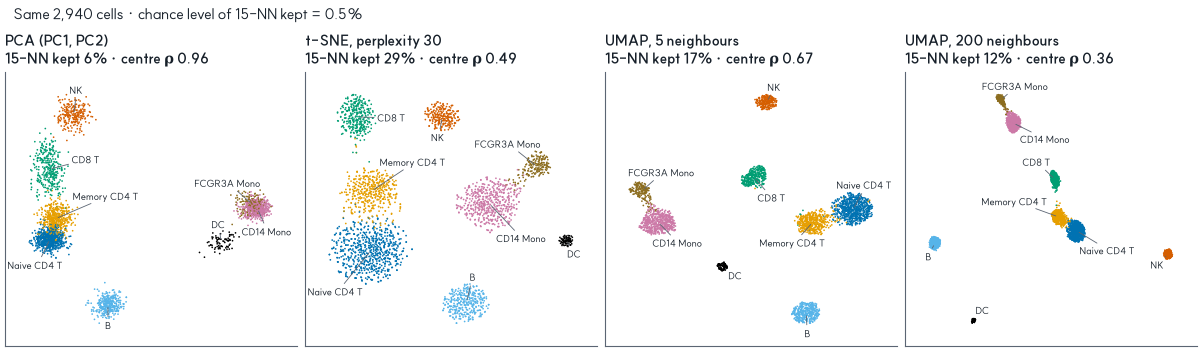

In [33]:
# Step B4.6 · four embeddings side by side, labelled directly, with both numbers in every title
show = [n for n in embeddings if n != "UMAP, 15 neighbours"]
fig, axs = plt.subplots(1, 4, figsize=(12, 3.5), layout="constrained")
for ax, name in zip(axs, show):
    emb, r = embeddings[name], summary_emb.loc[name]
    ax.scatter(emb[:, 0], emb[:, 1], s=1.5, c=[CT_COLORS[t] for t in cell_label], linewidths=0)
    label_clusters(ax, emb, cell_label, fontsize=7)
    ax.set_title(f"{name}\n15-NN kept {r['15-NN kept (%)']:.0f}% · centre ρ {r['centre-distance rho']:.2f}")
    ax.set(xticks=[], yticks=[])
fig.suptitle(f"Same {len(cells):,} cells · chance level of 15-NN kept = {chance:.1f}%", x=0.01, ha="left", color=dviz.INK)
dviz.savefig(fig, "B4_neighbourhoods")
plt.show()

**What changed?** Same cells, same names, five maps (the four above and the UMAP of Step B4.5) – and the two kinds of structure behave in opposite ways.
**Neighbours:** t-SNE and the UMAPs keep from 12% (UMAP, 200 neighbours) to 29% (t-SNE, perplexity 30) of each
cell's 15 nearest neighbours, 24 to
57 times the chance level of 0.5%, and
98.0% or more of the neighbours on these maps carry the same name. The linear view (PC1, PC2) keeps only
6%. **Distances:** PC1–PC2 keeps the order of the 28 cluster-centre distances
(ρ = 0.96), but t-SNE and UMAP do not: ρ = 0.36 (UMAP, 200 neighbours) to 0.67
(UMAP, 5 neighbours). The "most isolated cluster" changes with the method and its settings.

**Your turn.** A colleague points at the UMAP of Step B4.5 and says: "B cells are the most different cell type,
because their island is the farthest from the others." Use the table: is that justified?

<details><summary>Answer</summary>

No. On that UMAP (15 neighbours) the most isolated island is **B**, but in the
30-PC space the most isolated cluster is **NK**, and the answer changes with the
method: 30 PCs (reference): **NK**; PCA (PC1, PC2): **NK**; t-SNE, perplexity 30: **CD8 T**; UMAP, 15 neighbours: **B**; UMAP, 5 neighbours: **NK**; UMAP, 200 neighbours: **NK**. The position of an island is a property of the map, not of the cells. To ask how different two cell
types are, use the 30-PC (or gene) space, for example distances there or the number of differentially expressed genes.
On a t-SNE or UMAP, trust the neighbours and the existence of groups, not gaps, sizes or positions.
</details>

## Step B4.7 · Draw order: what the reader can see  *(1 min · Visualize)*

**Why this step.** In a scatter plot of thousands of cells the points overlap, and the last ones drawn are on top. If
the cells with zero expression are drawn last, they cover the cells that express the gene, and a real signal looks
weak or absent. Seurat's `FeaturePlot(order = TRUE)` and sorting by value before plotting fix this.

**New terms**
* **Feature plot** – an embedding coloured by the expression of one gene.
* **Draw order** – the order in which points are painted; later points cover earlier ones.
* **Visible share** – put a 60 × 60 grid over the plot: in each square you only see the cell drawn last. The visible
  share is the % of occupied squares whose top cell expresses the gene.

In [34]:
# Step B4.7 · helper: how much of a signal is visible after drawing
def visible_share(xy, values, order, bins=60):
    """Put a bins x bins grid over the plot. In each square a reader sees only the cell drawn last.
    Returns the share of occupied squares whose visible (last-drawn) cell has a value > 0."""
    xy, v = np.asarray(xy)[order], np.asarray(values)[order]
    ij = np.floor((xy - xy.min(axis=0)) / np.ptp(xy, axis=0) * (bins - 1e-9)).astype(int)
    square = ij[:, 0] * bins + ij[:, 1]
    top = pd.Series(v).groupby(square).last()        # rows are in drawing order: last = on top
    return float((top > 0).mean())

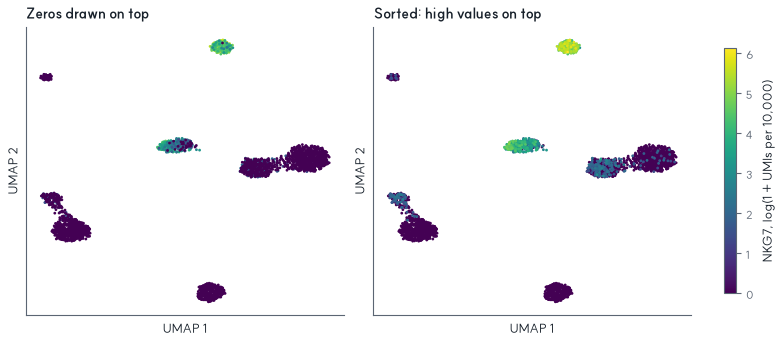

In [35]:
# Step B4.7 · NKG7 (natural killer granule protein 7) on the UMAP: zeros on top vs sorted
nkg7 = lognorm[:, int(np.flatnonzero(gene_names == "NKG7")[0])]
orders = {"Zeros drawn on top": np.argsort(-nkg7, kind="stable"),          # high values first, zeros last
          "Sorted: high values on top": np.argsort(nkg7, kind="stable")}  # zeros first, high values last
fig, axs = plt.subplots(1, 2, figsize=(7.8, 3.4), layout="constrained")
for ax, (title, order) in zip(axs, orders.items()):
    dots = ax.scatter(umap15[order, 0], umap15[order, 1], c=nkg7[order], s=4, cmap="viridis",
                      vmin=0, vmax=float(nkg7.max()), linewidths=0)
    ax.set(title=title, xticks=[], yticks=[], xlabel="UMAP 1", ylabel="UMAP 2")
fig.colorbar(dots, ax=axs, label="NKG7, log(1 + UMIs per 10,000)", shrink=0.85)
dviz.savefig(fig, "B4_draw_order")
plt.show()

In [36]:
# CHECK · NKG7 by true type, and how much of the NKG7 signal a reader can see in each panel
nk_umis = counts_kept[:, int(np.flatnonzero(gene_names == "NKG7")[0])].toarray().ravel()
by_type = pd.Series(nk_umis > 0).groupby(true_type).mean().mul(100).round(1).loc[CELL_TYPES]
print("cells with NKG7 > 0 (%):", by_type.to_dict())
dviz.check("B4.nkg7_umis_in_B_and_CD14", int(nk_umis[np.isin(true_type, ["B", "CD14 Mono"])].sum()), 0,
           note="all-zero groups")
dviz.check("B4.nkg7_pct_nk", float(by_type["NK"]), between=(90, 100), note="% of NK cells with NKG7")
seen = {title: 100 * visible_share(umap15, nkg7, order) for title, order in orders.items()}
seen["File order (unsorted)"] = 100 * visible_share(umap15, nkg7, np.arange(len(nkg7)))
print("visible share (% of occupied squares with NKG7 > 0):", {k: round(x, 1) for k, x in seen.items()})
dviz.check("B4.visible_gain", round(seen["Sorted: high values on top"] / seen["Zeros drawn on top"], 2),
           between=(1.5, 100), note="sorted / zeros on top")

cells with NKG7 > 0 (%): {'Naive CD4 T': 3.4, 'Memory CD4 T': 33.0, 'CD8 T': 90.8, 'NK': 99.6, 'B': 0.0, 'CD14 Mono': 0.0, 'FCGR3A Mono': 42.9, 'DC': 11.4}
CHECK ✓ B4.nkg7_umis_in_B_and_CD14 = 0   (reference: 0)  all-zero groups
CHECK ✓ B4.nkg7_pct_nk = 99.6   (reference: in [90, 100])  % of NK cells with NKG7
visible share (% of occupied squares with NKG7 > 0): {'Zeros drawn on top': 14.3, 'Sorted: high values on top': 51.0, 'File order (unsorted)': 27.9}
CHECK ✓ B4.visible_gain = 3.56   (reference: in [1.5, 100])  sorted / zeros on top


True

**What changed?** Same cells, same colour scale, different order. With zeros on top only
14% of the occupied squares show an
NKG7-expressing cell; sorted, 51%
(3.6 times more). NKG7 is found in 99.6% of NK cells and in
no B cell or CD14 monocyte at all: these two groups are entirely zero.

**Your turn.** Seurat's FeaturePlot draws the cells in data order unless you set `order = TRUE`. Which panel does that
resemble? And what would a violin plot of NKG7 in B cells show?

<details><summary>Answer</summary>

In data order (our file is sorted by barcode, i.e. random with respect to NKG7) the visible share is
28%: between the two panels, so part of
the signal is still hidden. A violin of an all-zero group has no shape at all (a flat line at 0). If a tool adds tiny
random noise before estimating the density – Seurat's VlnPlot does – it draws a violin shape that comes from the
noise, not from the data (lecture slide 21).
</details>

## Summary

In [37]:
# Summary · what each step did, and the number that shows it worked
summary = pd.DataFrame([
    ("B4.1 QC", "UMIs and genes per cell", f"median {np.median(umis_per_cell):,.0f} UMIs; {pct_zeros:.1f}% zeros"),
    ("B4.2 Normalise, HVG, PCA", "10,000 + log1p; 1,000 HVGs; 30 PCs", f"PC1-PC3 explain {100 * var_ratio[:3].sum():.0f}%"),
    ("B4.3 UMAP, t-SNE", "2-D maps of the 30 PCs", f"UMAP {umap_seconds:.1f} s; t-SNE {tsne_seconds:.1f} s"),
    ("B4.4 k-means", "k = 8 on 30 PCs vs truth", f"ARI {ari:.3f}"),
    ("B4.5 Dot plot", "marker genes -> names", f"{100 * correct.mean():.1f}% of cells named correctly"),
    ("B4.6 Neighbourhoods", "15-NN kept and centre distances",
     f"15-NN kept {nonlinear['15-NN kept (%)'].min():.0f}-{nonlinear['15-NN kept (%)'].max():.0f}% "
     f"(chance {chance:.1f}%); rho {rho.min():.2f} to {rho.max():.2f}"),
    ("B4.7 Draw order", "NKG7: zeros on top vs sorted",
     f"visible {seen['Zeros drawn on top']:.0f}% -> {seen['Sorted: high values on top']:.0f}%"),
], columns=["step", "what you did", "number"])
print(summary.to_string(index=False))

                    step                       what you did                                            number
                 B4.1 QC            UMIs and genes per cell                    median 2,188 UMIs; 91.3% zeros
B4.2 Normalise, HVG, PCA 10,000 + log1p; 1,000 HVGs; 30 PCs                               PC1-PC3 explain 56%
        B4.3 UMAP, t-SNE             2-D maps of the 30 PCs                           UMAP 8.0 s; t-SNE 2.7 s
            B4.4 k-means           k = 8 on 30 PCs vs truth                                         ARI 0.962
           B4.5 Dot plot              marker genes -> names                    98.5% of cells named correctly
     B4.6 Neighbourhoods    15-NN kept and centre distances 15-NN kept 12-29% (chance 0.5%); rho 0.36 to 0.96
         B4.7 Draw order       NKG7: zeros on top vs sorted                                visible 14% -> 51%


### Presentation sentence

Fill in one sentence of each kind for your pair's slide:

> **Question** – … **Takeaway with a number** – … **Limitation** – …

<details><summary>Example</summary>

**Question:** which immune cell types are in 2,940 simulated blood cells, and what can a UMAP of them show?
**Takeaway:** k-means on 30 PCs recovers the 8 planted types (ARI 0.96; 98.5%
of the cells named correctly from marker genes), and t-SNE and UMAP keep 12–29% of each cell's 15
nearest neighbours (chance 0.5%), whereas the order of the distances between clusters agrees with the
30-PC space only partly (ρ = 0.36 to 0.67) and changes with the method and its settings. **Limitation:** simulated cells with clean,
discrete types; real data add doublets, ambient RNA, batch effects and continuous states, and k has to be chosen.
</details>

In [38]:
# Step B4 · collect the numbers for the slides (value, unit, meaning)
sn = {"n_cells": (int(counts.shape[0]), "cells", "cells in the count matrix"),
      "n_genes": (int(counts.shape[1]), "genes", "genes in the count matrix (real MANE Select genes)"),
      "median_umis_per_cell": (float(np.median(umis_per_cell)), "UMIs", "median library size"),
      "pct_zeros": (round(pct_zeros, 1), "%", "matrix entries that are 0"),
      "ari": (round(ari, 3), "", "adjusted Rand index, k-means (k = 8) on 30 PCs vs truth"),
      "pct_correctly_labelled": (round(100 * correct.mean(), 1), "%", "cells whose marker-based name equals the truth"),
      "pct_cd14_mono": (float(per_type.loc["CD14 Mono", "truth (%)"]), "% of cells", "CD14 monocytes (truth file)"),
      "pct_memory_cd4_t": (float(per_type.loc["Memory CD4 T", "truth (%)"]), "% of cells", "memory CD4 T cells (truth file)"),
      "umap_settings": (UMAP_SETTINGS, "", "input and parameters of the UMAP"),
      "umap_runtime_s": (round(umap_seconds, 1), "s", "UMAP run time, 15 neighbours (first call, incl. compilation)"),
      "tsne_runtime_s": (round(tsne_seconds, 1), "s", "t-SNE run time, perplexity 30"),
      "knn15_chance_pct": (round(chance, 2), "%", "15-NN kept by a random 2-D layout"),
      "same_label_neighbours_min_pct": (float(nonlinear["same-label neighbours (%)"].min()), "%",
                                        "lowest share of same-name neighbours over t-SNE and UMAP maps")}
for name, r in summary_emb.drop(index="30 PCs (reference)").iterrows():
    sn[f"knn15_kept_{KEY[name]}_pct"] = (float(r["15-NN kept (%)"]), "%", f"{name}: 15 nearest neighbours (30 PCs) kept in 2-D")
    sn[f"centre_rho_{KEY[name]}"] = (float(r["centre-distance rho"]), "Spearman rho",
                                     f"{name}: order of the 28 cluster-centre distances vs 30-PC space")
    sn[f"most_isolated_{KEY[name]}"] = (r["most isolated cluster"], "", f"{name}: largest mean distance to other centres")
sn["most_isolated_pcs30"] = (summary_emb.loc["30 PCs (reference)", "most isolated cluster"], "", "30 PCs: largest mean distance")
slide_numbers = {k: {"value": x, "unit": u, "meaning": m} for k, (x, u, m) in sn.items()}

In [39]:
# Step B4 · save every CHECK value and the slide numbers to results/B4.json, and the cluster names per cell
settings = {"genes": "detected in >= 3 cells", "normalise": "counts per 10,000, then log1p",
            "hvg": "1,000 genes, dispersion z-score in 20 bins of mean", "pca": "30 PCs, centred, not scaled",
            "kmeans": {"k": 8, "n_init": 10, "seed": SEED}, "tsne": {"perplexity": 30, "init": "pca", "seed": SEED},
            "umap": {"n_neighbors": 15, "min_dist": 0.3, "seed": SEED, "input": "30 PCs", "computed": HAS_UMAP}}
seen_short = {"visible_zeros_on_top_pct": round(seen["Zeros drawn on top"], 1),
              "visible_sorted_pct": round(seen["Sorted: high values on top"], 1),
              "visible_file_order_pct": round(seen["File order (unsorted)"], 1)}
slide_numbers["visible_nkg7_zeros_on_top_pct"] = {"value": seen_short["visible_zeros_on_top_pct"], "unit": "%", "meaning": "grid squares whose top cell has NKG7 > 0, zeros drawn last"}
slide_numbers["visible_nkg7_sorted_pct"] = {"value": seen_short["visible_sorted_pct"], "unit": "%", "meaning": "same, cells sorted by NKG7 (high values last)"}
dviz.save_results("B4", extra={
    "settings": settings, "slide_numbers": slide_numbers, "markers_not_in_hvg": missed,
    "embeddings": summary_emb.reset_index().to_dict(orient="records"), "visible_share_pct_short": seen_short,
    "per_type": per_type.to_dict(orient="index"), "nkg7_pct_by_type": by_type.to_dict(),
    "confusion_named": pd.crosstab(pd.Series(true_type, name="truth"), pd.Series(cell_label, name="name")).to_dict(orient="index"),
    "dotplot_pct": pct.loc[rows].rename(index=cluster_label).round(1).to_dict(orient="index"),
    "dotplot_mean": mean.loc[rows].rename(index=cluster_label).round(3).to_dict(orient="index"),
    "seconds_before_save": round(time.time() - T_START, 1)})
pd.DataFrame({"cell_id": cells["cell_id"], "cluster": cluster, "cluster_name": cell_label}).to_csv(
    dviz.RESULTS / "B4_clusters.tsv", sep="\t", index=False)        # input for prompt card 4, part B
print(f"Notebook time: {time.time() - T_START:.0f} s")

saved results/B4.json  (47 values, 0 failed checks)
Notebook time: 33 s
